# RoadSafe Chicago | Partie 05 : Analyse exploratoire bivariée

**Projet** : étude de l'accidentologie routière à Chicago (Open Data, API Socrata)
**Données** : 112 056 accidents enregistrés en 2024 (`data/processed/crashes_2024.parquet`)
**Problématique** : *Comment évoluent la fréquence et la gravité des accidents routiers à Chicago, et quels facteurs sont associés à leur gravité ?*

---

### Objectif

La partie 04 a décrit **combien** d'accidents surviennent, et dans quelles conditions. Cette partie s'intéresse à une autre question : **quelle part de ces accidents est grave**, selon le contexte ?

On passe ainsi du **volume** au **taux** : un contexte peut concentrer peu d'accidents tout en présentant une gravité nettement plus élevée.

### Mesure utilisée

- **Variable de gravité principale** : `is_severe`, accident mortel ou avec au moins un blessé grave. Les accidents mortels seuls sont trop rares pour des comparaisons fiables sur une année.
- **Indicateur** : taux d'accidents graves dans chaque groupe = accidents graves du groupe / accidents du groupe.
- Chaque taux est présenté avec son **effectif** et son **intervalle de confiance à 95 %**.

### Sommaire

1. Gravité selon l'heure de la journée
2. Gravité selon le jour de la semaine
3. Gravité selon la luminosité
4. Gravité selon la limite de vitesse affichée
5. Gravité selon la météo et l'état de la chaussée
6. Gravité selon le type de collision
7. Tableau récapitulatif

### Précautions de lecture

- Les modalités **UNKNOWN** sont exclues des comparaisons, et les groupes de moins de 200 accidents ne sont pas affichés.
- Un écart entre deux taux n'est interprété que

## Librairies 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Importation et affichage des données

df = pd.read_parquet("../data/processed/crashes_2024.parquet")
df.head()

,crash_record_id,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,...,delay_valid,injury_info_available,is_injury,is_fatal,is_severe,is_weekend,time_slot,season,is_dark,speed_class
0,5082d6e9f9c5c96660e7ec7fd416549e50d3130af3fc5c...,2024-06-27 13:45:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Journée (10-15h),Été,False,≤20
1,fd34aa4f12f00106b32134531fc6e805590dbe89fef502...,2024-06-22 18:07:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,NOT DIVIDED,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Soir (16-19h),Été,False,25-30
2,f0a652bf48a8c08c8a26cc981e39ed757cd41f8a771761...,2024-06-23 08:41:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,REAR TO REAR,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Matin (6-9h),Été,False,≤20
3,973cda531480f4006c44691e5cc8931b9fd9d719a21264...,2024-06-19 07:35:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,TURNING,T-INTERSECTION,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Matin (6-9h),Été,False,25-30
4,e66fd58b2afc22ec6aa176f149d17467d49f7ae1c83910...,2024-07-07 20:47:00,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PARKED MOTOR VEHICLE,OTHER,STRAIGHT AND LEVEL,...,True,True,True,False,False,True,Nuit (20-23h),Été,True,25-30


In [3]:




jours_labels = {1: "Dimanche", 2: "Lundi", 3: "Mardi", 4: "Mercredi", 5: "Jeudi", 6: "Vendredi", 7: "Samedi"}
ordre_jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def wilson(k, n, z=1.96):
    """Intervalle de confiance de Wilson pour une proportion (fiable même pour des taux faibles)."""
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    marge = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - marge, centre + marge

def taux_par_groupe(col, cible="is_severe", min_n=200, exclure=("UNKNOWN",), data=None):
    """Taux de la cible par modalité, avec effectif et IC à 95 %."""
    d = (df if data is None else data)[[col, cible]].dropna()
    d = d[~d[col].astype(str).isin(exclure)]
    g = d.groupby(col, observed=True)[cible].agg(n="count", k="sum").astype(float)
    g = g[g["n"] >= min_n]
    g["taux"] = g["k"] / g["n"] * 100
    bas, haut = wilson(g["k"], g["n"])
    g["ic_bas"], g["ic_haut"] = bas * 100, haut * 100
    return g

def plot_taux(g, titre, nom, cible="is_severe", trier=True, label="% d'accidents graves"):
    """Barres horizontales avec IC, effectifs et moyenne globale."""
    if trier:
        g = g.sort_values("taux")
    moyenne = df[cible].mean() * 100
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(g) + 1.8))
    erreurs = [g["taux"] - g["ic_bas"], g["ic_haut"] - g["taux"]]
    ax.barh(g.index.astype(str), g["taux"], xerr=erreurs, color="steelblue", capsize=3)
    ax.axvline(moyenne, color="crimson", linestyle="--", label=f"Moyenne globale : {moyenne:.2f} %")
    for i, (haut, n) in enumerate(zip(g["ic_haut"], g["n"])):
        ax.text(haut + 0.05, i, f"n = {int(n):,}".replace(",", " "), va="center", fontsize=9, color="gray")
    ax.set_xlim(0, g["ic_haut"].max() * 1.3)
    ax.set_title(titre, fontweight="bold"); ax.set_xlabel(label); ax.legend(loc="lower right")
    save_fig(nom)

print("Taux global d'accidents graves :", round(df["is_severe"].mean() * 100, 2), "%")

Taux global d'accidents graves : 1.56 %


## 1. Gravité selon l'heure de la journée

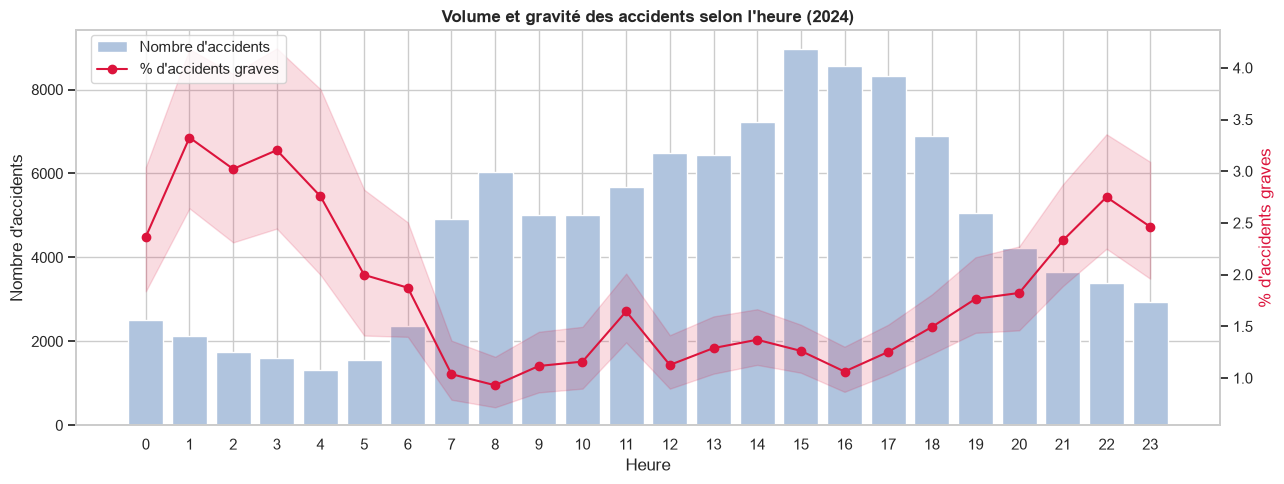

In [4]:
# Gravité des accidents selon l'heure

g = taux_par_groupe("crash_hour", min_n=0)
volume = df["crash_hour"].value_counts().sort_index()

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(volume.index, volume.values, color="lightsteelblue", label="Nombre d'accidents")
ax1.set_xlabel("Heure"); ax1.set_ylabel("Nombre d'accidents"); ax1.set_xticks(range(24))

ax2 = ax1.twinx()
ax2.plot(g.index, g["taux"], color="crimson", marker="o", label="% d'accidents graves")
ax2.fill_between(g.index, g["ic_bas"], g["ic_haut"], color="crimson", alpha=0.15)
ax2.set_ylabel("% d'accidents graves", color="crimson"); ax2.grid(False)

ax1.set_title("Volume et gravité des accidents selon l'heure (2024)", fontweight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
save_fig("05_1_gravite_par_heure")

**Analyse.** Le volume et la gravité évoluent en sens inverse. Les heures de pointe concentrent le plus d'accidents mais les moins graves (0,93 % à 8 h, autour de 1,1 à 1,3 % l'après midi) : une circulation dense limite les vitesses. La nuit, entre 1 h et 3 h, le taux d'accidents graves dépasse 3 %, soit le double de la moyenne. Plusieurs explications sont plausibles : vitesses plus élevées sur des voies dégagées, fatigue, alcool. L'heure étant liée à la luminosité, les deux effets sont démêlés en partie 06.

## 2. Gravité selon le jour de la semaine

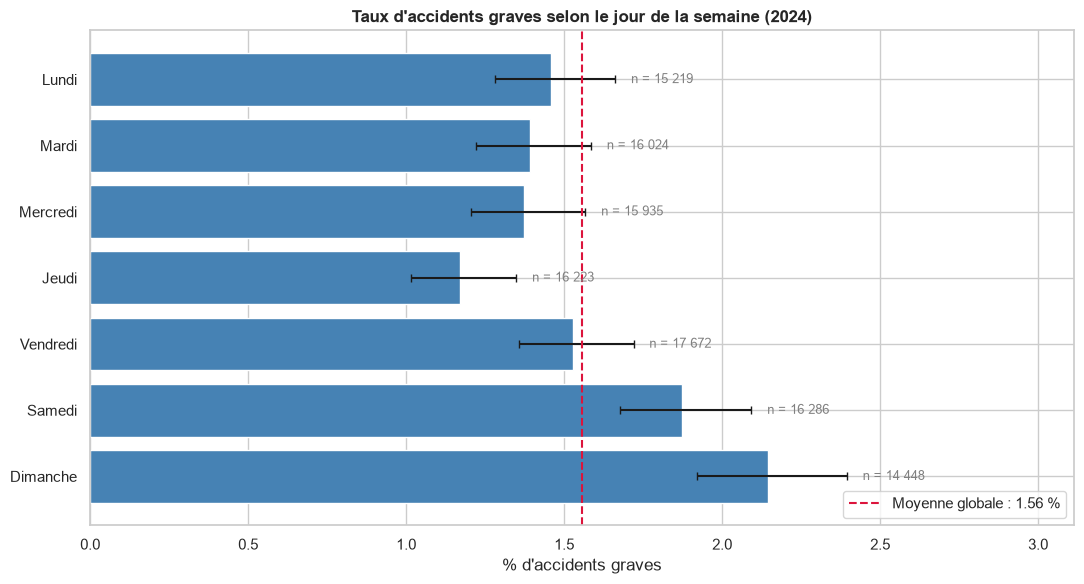

In [5]:
# Gravité des accidents selon le jour de la semaine
g = taux_par_groupe("jour", data=df.assign(jour=df["crash_day_of_week"].map(jours_labels)))
g = g.reindex(ordre_jours[::-1])  # lundi en haut
plot_taux(g, "Taux d'accidents graves selon le jour de la semaine (2024)",
          "05_2_gravite_par_jour", trier=False)

**Analyse.** Le week-end est plus grave : 2,15 % d'accidents graves le dimanche et 1,87 % le samedi, contre 1,17 à 1,53 % en semaine (minimum le jeudi). Ce surcroît est cohérent avec le volume nocturne élevé du week-end observé en partie 04. L'effet reste significatif après ajustement sur les autres facteurs en partie 07 (odds ratio de 1,41).

## 3. Gravité selon la luminosité

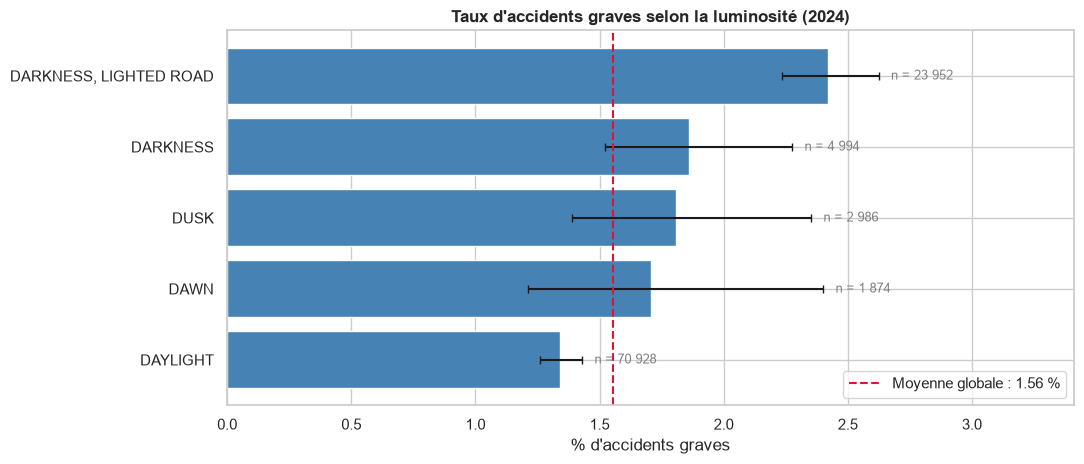

In [6]:
# Gravité des accidents selon la luminosité
g = taux_par_groupe("lighting_condition")
plot_taux(g, "Taux d'accidents graves selon la luminosité (2024)", "05_3_gravite_luminosite")

**Analyse.** De jour, 1,34 % des accidents sont graves. Tous les contextes de faible luminosité sont au dessus : aube 1,71 %, crépuscule 1,81 %, nuit sans éclairage 1,86 % et nuit sur voie éclairée 2,42 %. Le résultat contre intuitif (nuit éclairée plus grave que nuit non éclairée) ne signifie pas que l'éclairage aggrave les accidents : les voies éclairées sont les grands axes urbains, plus rapides et plus fréquentés par les piétons. L'écart entre les deux types de nuit est d'ailleurs à la limite de la significativité, et il est examiné par stratification en partie 06.

## 4. Gravité selon la limite de vitesse affichée

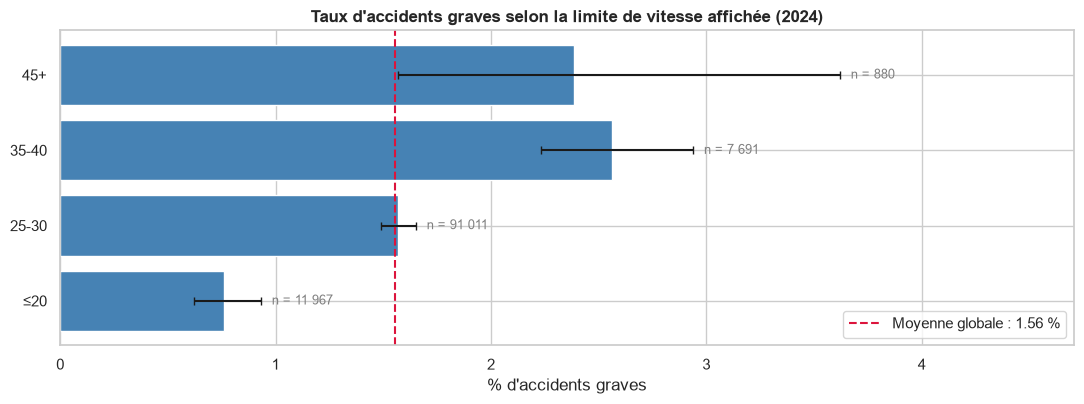

In [7]:
# Gravité des accidents selon la limite de vitesse affichée (limites valides uniquement)
g = taux_par_groupe("speed_class", data=df[df["speed_valid"]])
plot_taux(g, "Taux d'accidents graves selon la limite de vitesse affichée (2024)",
          "05_4_gravite_vitesse", trier=False)

**Analyse.** La gravité croît avec la limite affichée : 0,76 % sur les voies limitées à 20 mph ou moins, 1,57 % à 25-30 mph, 2,56 % à 35-40 mph. Un accident sur un axe à 35-40 mph est donc plus de trois fois plus souvent grave que dans une rue lente. La classe 45 mph et plus ne compte que 880 accidents : son intervalle de confiance est large et sa légère baisse par rapport à 35-40 mph n'est pas significative.

## 5. Gravité selon la météo et l'état de la chaussée

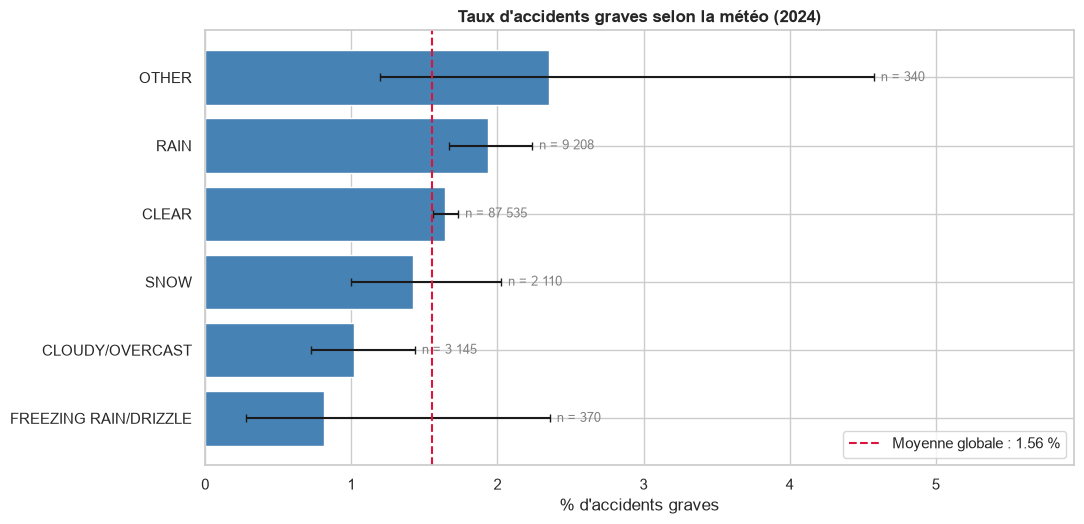

In [8]:
# Gravité des accidents selon la meteo

g = taux_par_groupe("weather_condition")
plot_taux(g, "Taux d'accidents graves selon la météo (2024)", "05_5a_gravite_meteo")

**Analyse.** Les écarts sont faibles et les intervalles de confiance se chevauchent largement : 1,64 % par temps clair, 1,93 % sous la pluie, 1,42 % sous la neige. Les modalités rares (pluie verglaçante, autre) reposent sur quelques accidents graves seulement (3 et 8) et ne doivent pas être interprétées. La météo apparaît comme un facteur de fréquence plus que de gravité. Le taux par temps clair dépasse la moyenne globale (1,56 %) car les accidents de météo inconnue, exclus ici, sont eux mêmes très peu graves (0,55 %).

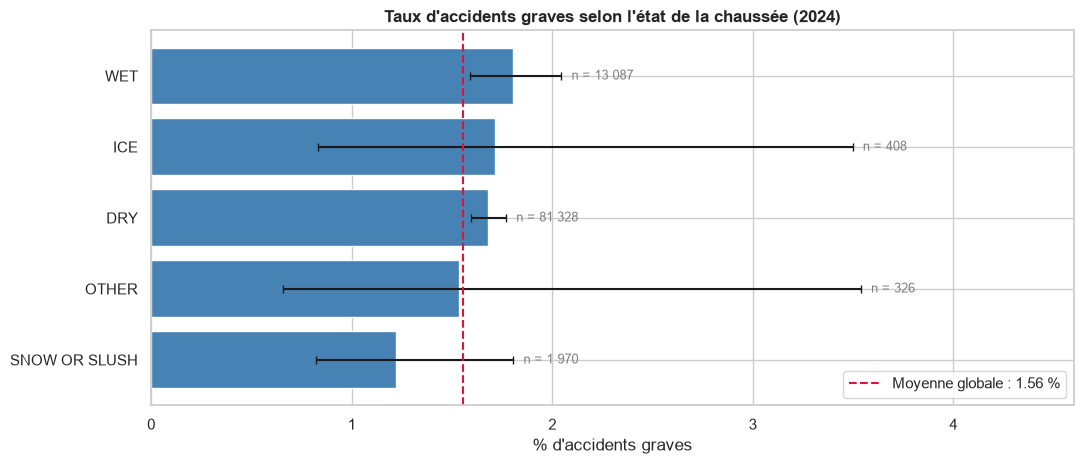

In [9]:
# Gravité des accidents selon l'état de la chaussée
g = taux_par_groupe("roadway_surface_cond")
plot_taux(g, "Taux d'accidents graves selon l'état de la chaussée (2024)", "05_5b_gravite_chaussee")

**Analyse.** Même constat pour la chaussée : chaussée mouillée (1,80 %) et sèche (1,68 %) sont très proches, et la neige est même en dessous (1,22 %). Une explication plausible est l'adaptation des conducteurs : on roule moins vite sur une route glissante, ce qui peut augmenter le nombre d'accidents sans en accroître la gravité.

## 6. Gravité selon le type de collision

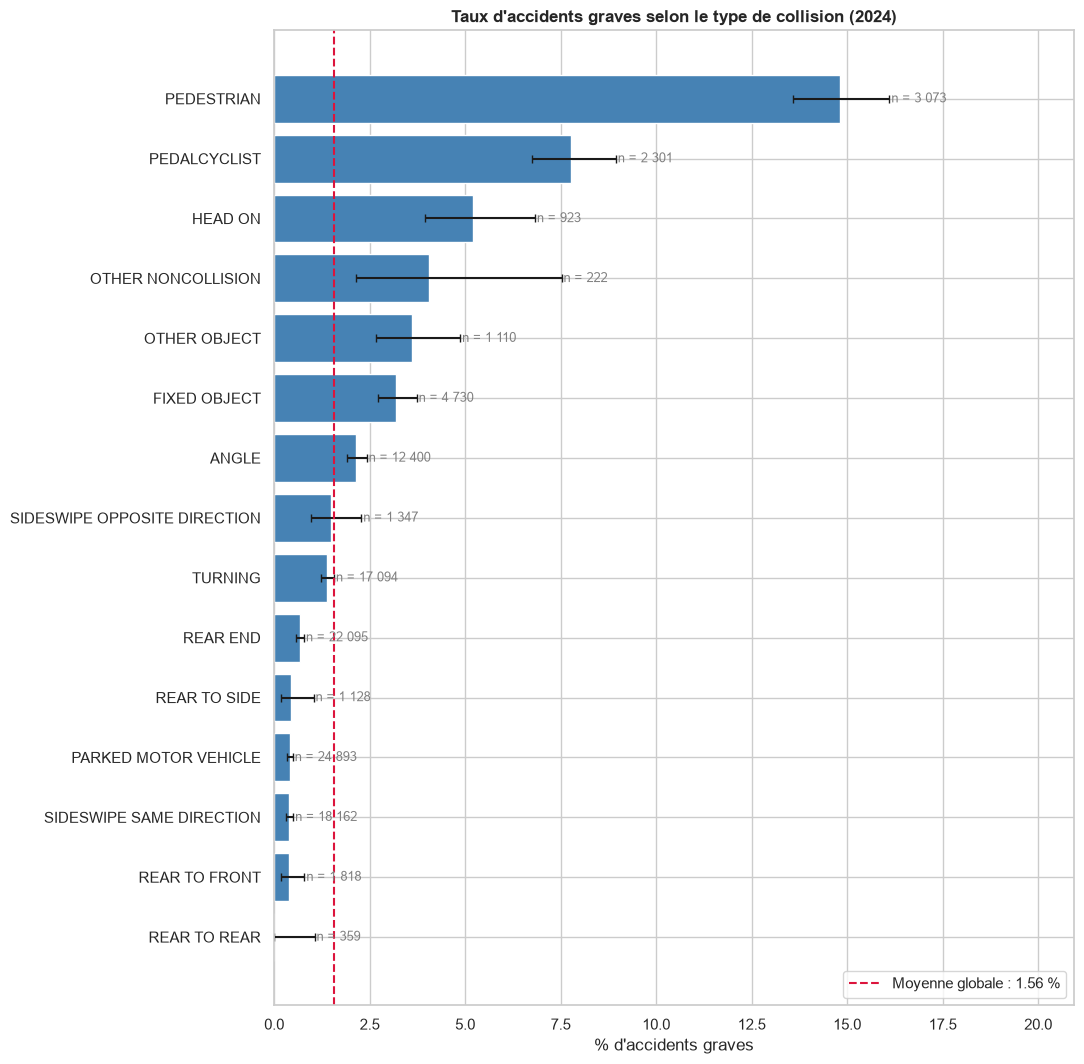

In [10]:
# Gravité des accidents selon le type de collision
g = taux_par_groupe("first_crash_type")
plot_taux(g, "Taux d'accidents graves selon le type de collision (2024)", "05_6_gravite_collision")

**Analyse.** C'est la variable la plus discriminante. Les collisions avec piétons sont graves dans **14,8 %** des cas, près de dix fois la moyenne, suivies des cyclistes (7,8 %) et des chocs frontaux (5,2 %). À l'opposé, les accrochages par l'arrière, latéraux ou contre un véhicule stationné sont graves dans moins de 0,7 % des cas. Piétons et cyclistes ne représentent que 4,8 % des accidents, mais **36 % des accidents graves** : la vulnérabilité des usagers pèse plus que les conditions extérieures.

## 7. Tableau récapitulatif

In [11]:
variables = {
    "Heure": "crash_hour",
    "Luminosité": "lighting_condition",
    "Vitesse affichée": "speed_class",
    "Météo": "weather_condition",
    "Chaussée": "roadway_surface_cond",
    "Type de collision": "first_crash_type",
}
recap = []
for nom, col in variables.items():
    g = taux_par_groupe(col)
    recap.append({
        "variable": nom,
        "taux_min_%": round(g["taux"].min(), 2), "modalité_min": g["taux"].idxmin(),
        "taux_max_%": round(g["taux"].max(), 2), "modalité_max": g["taux"].idxmax(),
        "ratio_max_min": round(g["taux"].max() / g["taux"].min(), 1),
    })

pd.DataFrame(recap).sort_values("ratio_max_min", ascending=False)

/tmp/ipykernel_82203/1110327489.py:16: RuntimeWarning: divide by zero encountered in scalar divide
  "ratio_max_min": round(g["taux"].max() / g["taux"].min(), 1),


,variable,taux_min_%,modalité_min,taux_max_%,modalité_max,ratio_max_min
5,Type de collision,0.00,REAR TO REAR,14.81,PEDESTRIAN,inf
0,Heure,0.93,8,3.33,1,3.6
2,Vitesse affichée,0.76,≤20,2.56,35-40,3.4
3,Météo,0.81,FREEZING RAIN/DRIZZLE,2.35,OTHER,2.9
1,Luminosité,1.34,DAYLIGHT,2.42,"DARKNESS, LIGHTED ROAD",1.8
4,Chaussée,1.22,SNOW OR SLUSH,1.80,WET,1.5


**Analyse.** Le type de collision domine nettement (de 0 % à 14,8 %). Viennent ensuite l'heure (rapport de 3,6 entre la nuit et les heures de pointe) et la vitesse affichée (3,4), puis la luminosité (1,8). Le ratio de la météo (2,9) est trompeur : ses deux extrêmes, pluie verglaçante et « autre », reposent sur 3 et 8 accidents graves seulement. Sur les modalités bien représentées, météo et chaussée présentent les écarts les plus faibles. Le ratio infini du type de collision vient de la modalité REAR TO REAR, sans aucun accident grave sur 359 cas.

## Bilan

- La gravité ne suit pas le volume : les contextes les plus fréquents (heures de pointe, jour, temps clair) sont les moins graves.
- **Facteurs associés à une gravité plus élevée** : collision avec piéton ou cycliste, nuit, limite de vitesse élevée, week-end.
- **Facteurs peu ou pas associés** : météo et état de la chaussée.
- Ces facteurs sont liés entre eux (la nuit, le trafic et les types de voie changent) : la partie 06 vérifie quels écarts résistent à la stratification.